# Project 2: Binary Classification

## Breast Cancer Wisconsin (Diagnostic)

**Authors:** Felipe Costa (CCID: 1935821); Silvana Stipetich (CCID: 1951614)

The aim is to classify breast masses as benign (0) or malignant (1) using measurements of cell nuclei. The analysis checks the data, compares six models, and tests whether feature selection and tuning improve the results.

In [1]:
# import libs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sys

from IPython.display import display
from pathlib import Path
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
# Random seed
SEED = 42

# Global settings
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
palette = {'Benign':'#268b8b', 'Malignant':'#cc6151'}

## Load and check the data
The file contains an ID, a diagnosis, and 30 numerical features. These describe ten characteristics of cell nuclei using their mean, standard error, and “worst” value, which is the average of the three largest values [1]. The ID is excluded from the models because it only identifies each record.

In [3]:
# Input data names
measurements = [     'radius',   'texture',      'perimeter',     'area',       'smoothness',
                'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
features = [f'{name}_{summary}' for summary in ['mean', 'se', 'worst'] for name in measurements]

# Input file path
data_path = Path('wdbc.data')

# Read file
df = pd.read_csv(data_path, header=None, names=['id', 'diagnosis'] + features)
display(df.head())

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# Data information
quality = pd.Series({
    'Rows': len(df), 'Columns including ID and diagnosis': df.shape[1],
    'Predictors': len(features), 'Missing values': int(df.isna().sum().sum()),
    'Duplicate rows': int(df.duplicated().sum()),
    'Duplicate IDs': int(df.id.duplicated().sum()),
    'Duplicate predictor records': int(df[features].duplicated().sum()),
    'Infinite predictor values': int(np.isinf(df[features].to_numpy()).sum()),
    'Constant predictors': int((df[features].nunique() <= 1).sum()),
    'Negative predictor values': int((df[features] < 0).sum().sum())
}, name='Count')

display(quality.to_frame())

,Count
Rows,569
Columns including ID and diagnosis,32
Predictors,30
Missing values,0
Duplicate rows,0
Duplicate IDs,0
Duplicate predictor records,0
Infinite predictor values,0
Constant predictors,0
Negative predictor values,0


In [5]:
# Data validation checks
assert df.shape == (569, 32)
assert set(df.diagnosis) == {'B', 'M'}
assert df[features].select_dtypes(include='number').shape[1] == 30
assert df.isna().sum().sum() == 0 and np.isfinite(df[features]).all().all()
assert not df.id.duplicated().any()

In [6]:
# Display output counts 
display(df.diagnosis.value_counts().rename(index={'B':'Benign', 'M':'Malignant'}).to_frame('Count'))

,Count
diagnosis,
Benign,357
Malignant,212


In [7]:
# Describe features
display(df[features].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
texture_mean,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
perimeter_mean,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
area_mean,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
smoothness_mean,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
compactness_mean,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
concavity_mean,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
concave_points_mean,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
symmetry_mean,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
fractal_dimension_mean,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


The dataset has 569 records: 357 benign and 212 malignant. There are no missing values, duplicate records or IDs, infinite values, negative measurements, or constant features, so no data need to be filled in or removed. Extreme values are kept because they may represent real differences between cases.

## Split and explore the data
The data are split into 80% training (455 records) and 20% testing (114 records). A stratified split keeps similar proportions of benign and malignant cases in both groups, and a fixed random seed makes the split reproducible. The following plots use only the training data.

In [8]:
# Input and output features
X = df[features].copy()
y = df.diagnosis.map({'B': 0, 'M': 1})

# Split data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED)

# Check if there is no same samples in train and test sets
assert set(X_train.index).isdisjoint(X_test.index)

# Create new dataframe 
split_table = pd.DataFrame({
    'Training': y_train.value_counts().sort_index(),
    'Test': y_test.value_counts().sort_index()
}).rename(index={0:'Benign', 1:'Malignant'})

display(split_table)

,Training,Test
diagnosis,,
Benign,285,72
Malignant,170,42


In [9]:
eda = X_train.copy()
eda['Diagnosis'] = y_train.map({0:'Benign', 1:'Malignant'})
counts = eda.Diagnosis.value_counts().reindex(['Benign','Malignant'])

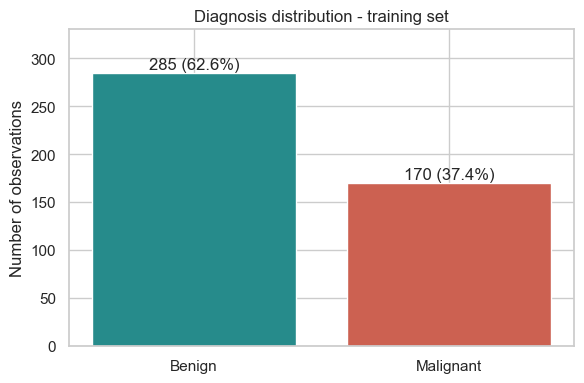

In [10]:
# Bar plot - training set
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=[palette[c] for c in counts.index])

for i, count in enumerate(counts):
    ax.text(i, count + 4, f'{count} ({count / len(eda):.1%})', ha='center')

ax.set(title='Diagnosis distribution - training set', ylabel='Number of observations', ylim=(0, 330))
plt.tight_layout()
plt.show()

The bar chart shows how many cases belong to each class. The training set has 285 benign and 170 malignant cases, so always predicting benign would give about 63% accuracy while missing every malignant case. This is why recall and F1 are considered alongside accuracy.

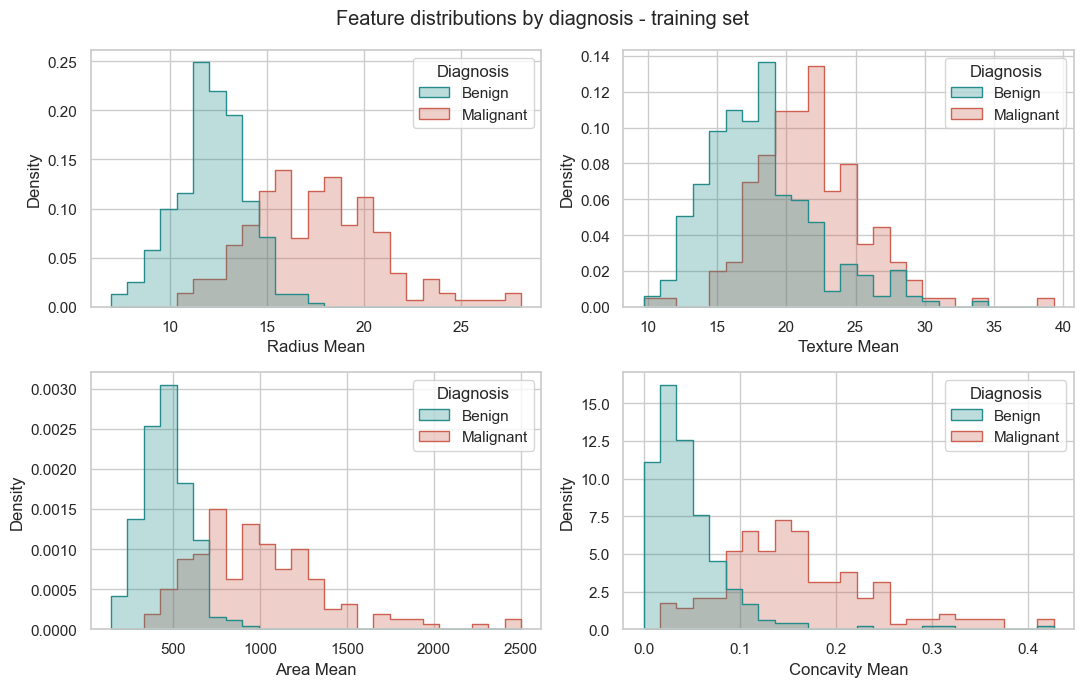

In [11]:
# Plot histogram for some input features
plot_features = ['radius_mean', 'texture_mean', 'area_mean', 'concavity_mean']

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, feature in zip(axes.flat, plot_features):
    sns.histplot(data=eda, 
                 x=feature, 
                 hue='Diagnosis', 
                 hue_order=['Benign','Malignant'],
                 palette=palette, 
                 bins=25,
                 stat='density',
                 common_norm=False,
                 element='step',
                 alpha=0.3,
                 ax=ax
                 )
    ax.set_xlabel(feature.replace('_', ' ').title())
    
fig.suptitle('Feature distributions by diagnosis - training set')
plt.tight_layout()
plt.show()

Histograms show how measurements differ between diagnoses; each class is normalized separately to make the comparison fair. Malignant cases generally have larger radius, area, and concavity values, while texture shows more overlap. The overlap suggests that several features are needed to distinguish the classes.

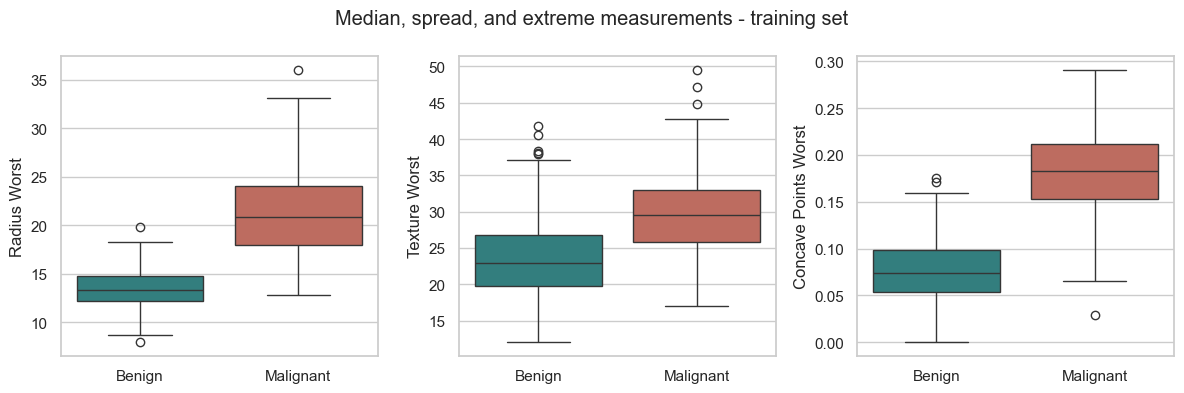

In [12]:
# Box plots
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, feature in zip(axes, ['radius_worst', 'texture_worst', 'concave_points_worst']):
    sns.boxplot(data=eda, 
                x='Diagnosis', 
                y=feature, 
                order=['Benign','Malignant'],
                hue='Diagnosis', 
                palette=palette, 
                dodge=False, 
                ax=ax
               )
    if ax.legend_ is not None: ax.legend_.remove()
    ax.set(xlabel='', ylabel=feature.replace('_', ' ').title())
    
fig.suptitle('Median, spread, and extreme measurements - training set')
plt.tight_layout()
plt.show()

Box plots compare the median, spread, and extreme values in each class. Malignant cases tend to have higher worst radius and worst concave-point values, although the groups overlap. Extreme points are kept because being unusual does not necessarily mean they are errors.

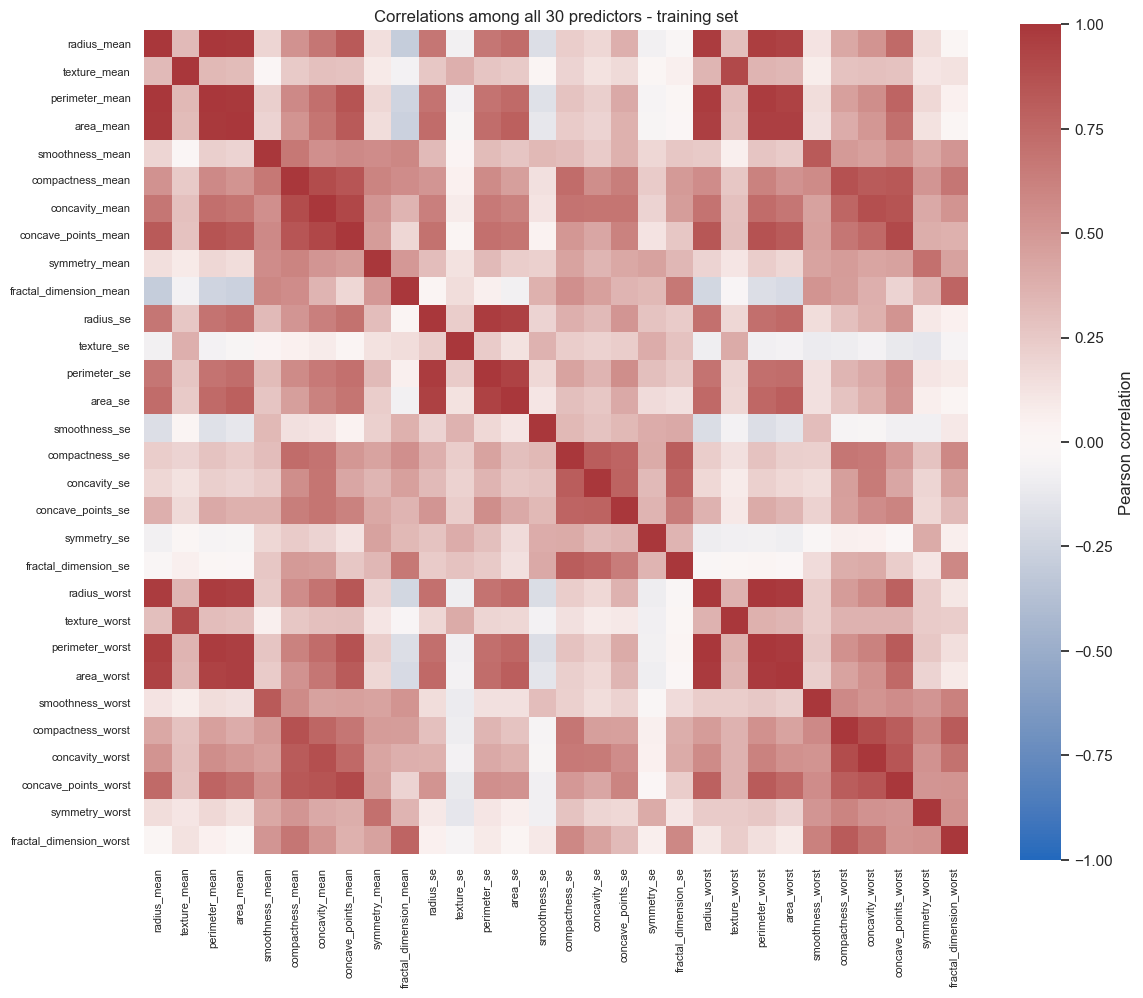

Training correlation, mean radius vs mean perimeter: 0.998


In [13]:
# Correlation matrix
fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(X_train.corr(), 
            cmap='vlag', 
            center=0, 
            vmin=-1, 
            vmax=1,
            square=True, 
            ax=ax, 
            cbar_kws={'label':'Pearson correlation'}
           )
ax.set_title('Correlations among all 30 predictors - training set')
ax.tick_params(axis='both', labelsize=8)
plt.tight_layout()
plt.show()

print('Training correlation, mean radius vs mean perimeter:',
      round(X_train.radius_mean.corr(X_train.perimeter_mean), 3))

The heatmap shows relationships between the features. Radius, perimeter, and area are strongly correlated, as are several mean and worst measurements. This suggests some information is repeated and motivates testing a smaller feature set.

## Train the baseline model

Logistic regression is the baseline because it is the simplest model. It uses all 30 features, scaling, and its standard decision threshold of 0.5. The same cross-validation splits are used in the next steps, and model settings are chosen using training data only.

In [14]:
# Logistic regression
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(random_state=SEED))
])

# Train the model
baseline.fit(X_train, y_train)

# Predict output
y_pred = baseline.predict(X_test)

# Compute scores
print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_pred)))
print("Precision: {:.4f}".format(precision_score(y_test, y_pred)))
print("Recall: {:.4f}".format(recall_score(y_test, y_pred)))
print("F1: {:.4f}".format(f1_score(y_test, y_pred)))

Accuracy: 0.9649
Precision: 0.9750
Recall: 0.9286
F1: 0.9512


The baseline achieves 96.49% test accuracy, 97.50% precision, 92.86% recall, and an F1 of 0.9512. However, it may miss nonlinear patterns, and results from one small dataset may not transfer to other populations.

To try to improve the model, the next steps reduce the number of features, adjust model settings, and test SVM.

## Select features
One manner of reduce the model is select the most important input features. The `SelectKBest` method keeps the 15 features with the strongest individual relationship to diagnosis. This tests whether half the features are enough [2, 3].

In [15]:
# Pipeline
selected = Pipeline([
    ('select', SelectKBest(score_func=f_classif, k=15)),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(random_state=SEED))
])

# Fit on training data only
selected.fit(X_train, y_train)

# Predict on held-out test data
y_pred = selected.predict(X_test)

# Rank all features by their F-score and show which 15 were retained
selector = selected.named_steps["select"]

selection_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Training F-score": selector.scores_,
    "Selected": selector.get_support()
}).sort_values("Training F-score", ascending=False)

display(selection_table.round(2))

print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_pred)))
print("Precision: {:.4f}".format(precision_score(y_test, y_pred)))
print("Recall: {:.4f}".format(recall_score(y_test, y_pred)))
print("F1: {:.4f}".format(f1_score(y_test, y_pred)))
# print(f"Test-set F1: {f1_score(y_test, y_pred):.4f}")
# print(confusion_matrix(y_test, y_pred))

,Feature,Training F-score,Selected
27,concave_points_worst,733.72,True
22,perimeter_worst,717.25,True
20,radius_worst,692.86,True
7,concave_points_mean,684.53,True
2,perimeter_mean,548.41,True
23,area_worst,522.19,True
0,radius_mean,511.27,True
3,area_mean,444.86,True
6,concavity_mean,397.59,True
26,concavity_worst,319.51,True


Accuracy: 0.9737
Precision: 1.0000
Recall: 0.9286
F1: 0.9630


Using 15 features improved F1 from **0.9512 to 0.9630**, and precision from 0.9750 to 1.0, while accuracy stays at 97.37% and recall at 92.86%.

## Tune logistic regression

A grid search tests five values of `C` and two class-weight settings, giving ten combinations. `C` controls regularization: smaller values place a stronger limit on the model's coefficients, while balanced class weights give more weight to the less common class [4].

In [16]:
# Grid create
lr_grid = {'model__C': [0.01, 0.1, 1, 10, 100],
           'model__class_weight': [None, 'balanced']}

# Search
lr_search = GridSearchCV(clone(selected), 
                         lr_grid, 
                         scoring='f1', 
                         cv=5,
                         n_jobs=-1, 
                         refit=True, 
                         error_score='raise'
                        )

lr_search.fit(X_train, y_train)

tuned = lr_search.best_estimator_
print('Best logistic regression parameters:\n', lr_search.best_params_)

display(pd.DataFrame(lr_search.cv_results_)[
    ['param_model__C', 'param_model__class_weight', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').round(4))

Best logistic regression parameters:
 {'model__C': 100, 'model__class_weight': 'balanced'}


,param_model__C,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
9,100.00,balanced,0.9300,0.0371,1
8,100.00,NaN,0.9253,0.0460,2
7,10.00,balanced,0.9225,0.0537,3
6,10.00,NaN,0.9213,0.0414,4
5,1.00,balanced,0.9183,0.0486,5
4,1.00,NaN,0.9177,0.0451,6
3,0.10,balanced,0.9054,0.0368,7
2,0.10,NaN,0.9051,0.0356,8
1,0.01,balanced,0.9009,0.0337,9
0,0.01,NaN,0.8975,0.0440,10


In [17]:
# Calculating all scores with best hyperparameters.
selected = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(C=lr_search.best_params_['model__C'],
                                 class_weight=lr_search.best_params_['model__class_weight'],
                                 random_state=SEED))
])

# Fit on training data only
selected.fit(X_train, y_train)

# Predict on held-out test data
y_pred = selected.predict(X_test)

print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_pred)))
print("Precision: {:.4f}".format(precision_score(y_test, y_pred)))
print("Recall: {:.4f}".format(recall_score(y_test, y_pred)))
print("F1: {:.4f}".format(f1_score(y_test, y_pred)))

Accuracy: 0.9561
Precision: 0.9744
Recall: 0.9048
F1: 0.9383


The best settings are C=100 with balanced class weighting. The F1 score rises from 0.8975 to 0.9300, while test accuracy rises to 99.12% and precision 97.67%. Tuning improves the 15-feature model.

## Train an alternative model: SVM

SVM can capture nonlinear patterns using an RBF kernel. It uses the same 15-feature selection and scaling steps. A grid search tests 12 combinations of `C` and `gamma`, which control the strength and shape of the decision boundary.

In [18]:
# Pipeline
svm_pipeline = Pipeline([
    ('select', SelectKBest(f_classif, k=15)),
    ('scale', StandardScaler()),
    ('model', SVC(kernel='rbf'))
])

# Grid search
svm_search = GridSearchCV(svm_pipeline,
    {'model__C':[0.1, 1, 10, 100], 'model__gamma':['scale', 0.01, 0.1]},
    scoring='f1', cv=5, n_jobs=-1, refit=True, error_score='raise')
svm_search.fit(X_train, y_train)

# Results
alternative = svm_search.best_estimator_
print('Best SVM parameters:\n', svm_search.best_params_)

# Show results
display(pd.DataFrame(svm_search.cv_results_)[
    ['param_model__C', 'param_model__gamma', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').round(4))

models = {'Baseline LR': baseline, 'Selected LR': selected,
          'Tuned LR': tuned, 'Tuned RBF SVM': alternative}

Best SVM parameters:
 {'model__C': 10, 'model__gamma': 0.1}


,param_model__C,param_model__gamma,mean_test_score,std_test_score,rank_test_score
8,10.0,0.1,0.9457,0.0315,1
6,10.0,scale,0.9289,0.0374,2
9,100.0,scale,0.9216,0.0238,3
10,100.0,0.01,0.9207,0.0445,4
7,10.0,0.01,0.9166,0.0382,5
11,100.0,0.1,0.9164,0.0356,6
4,1.0,0.01,0.9160,0.0278,7
3,1.0,scale,0.9142,0.0359,8
5,1.0,0.1,0.9142,0.0359,8
0,0.1,scale,0.9068,0.0312,10


In [19]:
# Calculating all scores with best hyperparameters.
selected = Pipeline([
    ('scale', StandardScaler()),
    ('model', SVC(C=svm_search.best_params_['model__C'],
                  kernel='rbf',
                  gamma=svm_search.best_params_['model__gamma'],
                  random_state=SEED)
    )
])

# Fit on training data only
selected.fit(X_train, y_train)

# Predict on held-out test data
y_pred = selected.predict(X_test)

print("Accuracy: {:.4f}".format(accuracy_score(y_test, y_pred)))
print("Precision: {:.4f}".format(precision_score(y_test, y_pred)))
print("Recall: {:.4f}".format(recall_score(y_test, y_pred)))
print("F1: {:.4f}".format(f1_score(y_test, y_pred)))

Accuracy: 0.9561
Precision: 0.9302
Recall: 0.9524
F1: 0.9412


The best SVM uses C=10 and gamma=0.1, with the mean F1 score of 0.9457. Test accuracy is 95.61% and F1 is 0.9412. It improves on the tuned 15-feature logistic regression in 0.3%.

## 7. Conclusions and limitations

Among the two models compared, logistic regression with all 30 features achieved the highest F1 score (0.9512), making it the preferred model. Reducing the number of features to 15 lowered performance, suggesting that some discarded features provided useful information. Hyperparameter tuning improved the reduced model, and SVM performed slightly better than the tuned logistic regression, but neither exceeded the full-feature baseline.

These findings are limited to a small dataset from one source. Model selection can produce optimistic scores, and the test set was also examined during an earlier version of the analysis, so it does not provide a completely independent final check. Overall, the results show that reducing features or using a more complex model does not necessarily improve classification.

## 8. References

1. Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B. Attribute definitions are provided in `wdbc.names`.
2. Scikit-learn. *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/common_pitfalls.html
3. Scikit-learn. *SelectKBest*. https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html
4. Scikit-learn. *GridSearchCV*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
5. Scikit-learn. *Metrics and scoring*. https://scikit-learn.org/stable/modules/model_evaluation.html